In [1]:
!wget 'https://raw.githubusercontent.com/nursace/ai-framework-slides/main/data/bytebrew-campus-cafe-orders.csv' -O bytebrew-campus-cafe-orders.csv

--2026-10-22 13:46:10--  https://raw.githubusercontent.com/nursace/ai-framework-slides/main/data/bytebrew-campus-cafe-orders.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 29943 (29K) [text/plain]
Saving to: ‘bytebrew-campus-cafe-orders.csv’

bytebrew-campus-caf 100%[===================>]  29.24K  --.-KB/s    in 0.004s  

2026-10-22 13:46:10 (7.91 MB/s) - ‘bytebrew-campus-cafe-orders.csv’ saved [29943/29943]



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('bytebrew-campus-cafe-orders.csv')

print('исходный размер:', df.shape)
print('дубликатов:', df.duplicated().sum())

df_clean = df.drop_duplicates().copy()

for column in ['tip', 'rating']:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print('после очистки:', df_clean.shape)
print('осталось пропусков:', df_clean.isna().sum().sum())

display(df_clean.head())

исходный размер: (365, 18)
дубликатов: 5
после очистки: (360, 18)
осталось пропусков: 0


,order_id,day_of_week,time_slot,student_year,faculty,drink,size,food_item,is_member,payment,raining,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
0,B0301,Tue,late_night,2,Bio,tea,L,croissant,no,card,no,4.49,8,288,0.10,3.0,1.9,1
1,B0266,Tue,morning,2,Bio,cappuccino,L,sandwich,no,campus_card,no,8.16,6,558,0.67,4.0,1.3,3
2,B0064,Fri,late_night,1,Business,hot_chocolate,S,cookie,no,campus_card,yes,4.08,8,382,0.84,4.0,4.8,0
3,B0197,Thu,afternoon,4,Business,americano,S,cookie,yes,card,no,3.19,6,194,0.89,4.0,3.2,0
4,B0261,Fri,morning,2,Design,americano,M,none,yes,card,no,2.48,5,11,0.79,3.0,4.7,1


5.1

In [3]:
mean_price = df_clean.groupby('is_member')['price'].mean()

print(mean_price.rename({
    'yes': 'с картой лояльности',
    'no': 'без карты лояльности'
}).round(2))

is_member
без карты лояльности    5.11
с картой лояльности     4.48
Name: price, dtype: float64


5.2

In [4]:
evening_night = df_clean[
    df_clean['time_slot'].isin(['evening', 'late_night'])
]

drink_counts = pd.crosstab(
    evening_night['drink'],
    evening_night['time_slot']
).reindex(columns=['evening', 'late_night'], fill_value=0)

drink_counts['total'] = drink_counts.sum(axis=1)

display(drink_counts.sort_values('total', ascending=False))

time_slot,evening,late_night,total
drink,,,
cold_brew,17,15,32
cappuccino,21,9,30
smoothie,17,9,26
americano,14,9,23
hot_chocolate,12,11,23
latte,9,12,21
tea,8,11,19


5.3

In [5]:
mean_prep = (
    df_clean.groupby('food_item')['prep_minutes']
    .mean()
    .sort_values()
)

print(mean_prep.round(2))

food_item
none         4.10
sandwich     6.90
cookie       6.95
soup         7.33
salad        7.51
croissant    7.57
Name: prep_minutes, dtype: float64


5.4

In [6]:
chocolate_stats = (
    df_clean.assign(
        hot_chocolate=df_clean['drink'].eq('hot_chocolate')
    )
    .groupby('raining')
    .agg(
        total_orders=('drink', 'size'),
        chocolate_orders=('hot_chocolate', 'sum'),
        chocolate_share=('hot_chocolate', 'mean')
    )
)

chocolate_stats['chocolate_share_percent'] = (
    chocolate_stats['chocolate_share'] * 100
)

display(
    chocolate_stats[
        ['total_orders', 'chocolate_orders',
         'chocolate_share_percent']
    ].round(2)
)

,total_orders,chocolate_orders,chocolate_share_percent
raining,,,
no,283,35,12.37
yes,77,10,12.99


5.5

In [7]:
year_stats = (
    df_clean.groupby('student_year')[['rating', 'tip']]
    .mean()
    .sort_index()
)

display(year_stats.round(3))

,rating,tip
student_year,,
1,3.877,0.533
2,3.903,0.612
3,3.989,0.605
4,3.860,0.525


5.6

In [8]:
faculty_calories = (
    df_clean.groupby('faculty')['calories']
    .mean()
    .sort_values(ascending=False)
)

print(faculty_calories.round(2))

faculty
Law         315.12
Arts        305.48
Business    301.94
CS          289.37
Design      281.46
Bio         274.17
Name: calories, dtype: float64


6.1

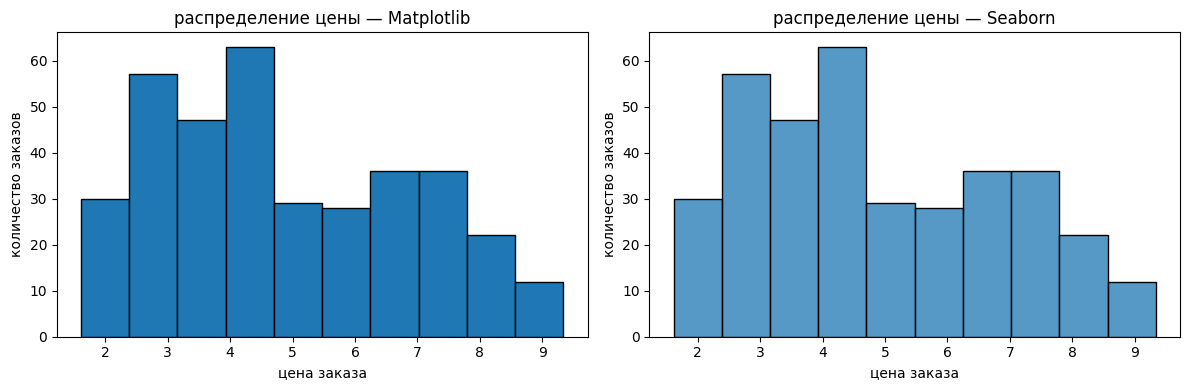

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

_, bins, _ = axes[0].hist(
    df_clean['price'],
    bins=10,
    edgecolor='black'
)

sns.histplot(
    data=df_clean,
    x='price',
    bins=bins,
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'распределение цены — {library}')
    ax.set_xlabel('цена заказа')
    ax.set_ylabel('количество заказов')

plt.tight_layout()
plt.show()

6.2

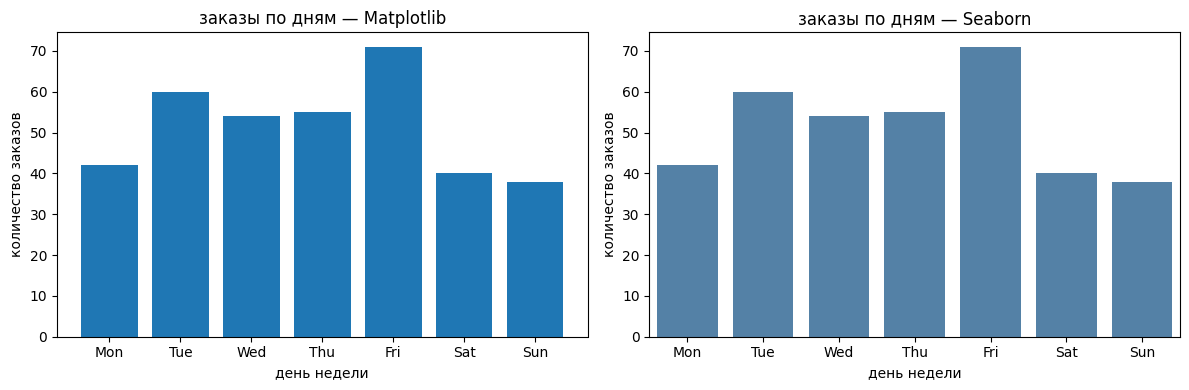

In [10]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

day_counts = (
    df_clean['day_of_week']
    .value_counts()
    .reindex(days, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(day_counts.index, day_counts.values)

sns.countplot(
    data=df_clean,
    x='day_of_week',
    order=days,
    color='steelblue',
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'заказы по дням — {library}')
    ax.set_xlabel('день недели')
    ax.set_ylabel('количество заказов')

plt.tight_layout()
plt.show()

6.3

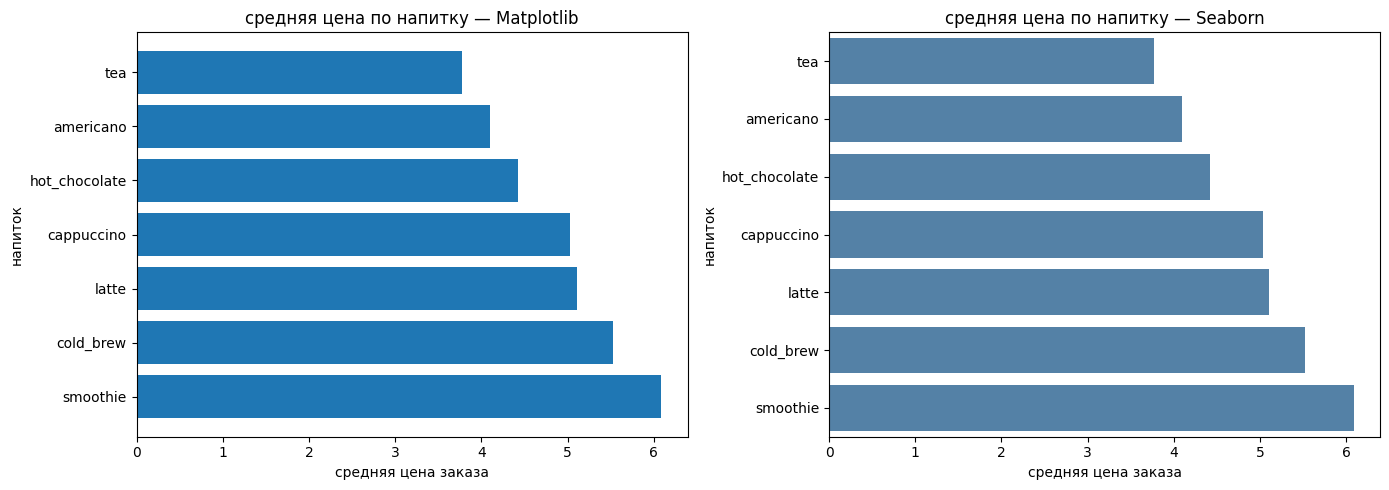

In [11]:
drink_prices = (
    df_clean.groupby('drink')['price']
    .mean()
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(drink_prices.index, drink_prices.values)
axes[0].invert_yaxis()

sns.barplot(
    data=drink_prices.rename('mean_price').reset_index(),
    x='mean_price',
    y='drink',
    order=drink_prices.index,
    color='steelblue',
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'средняя цена по напитку — {library}')
    ax.set_xlabel('средняя цена заказа')
    ax.set_ylabel('напиток')

plt.tight_layout()
plt.show()

6.4

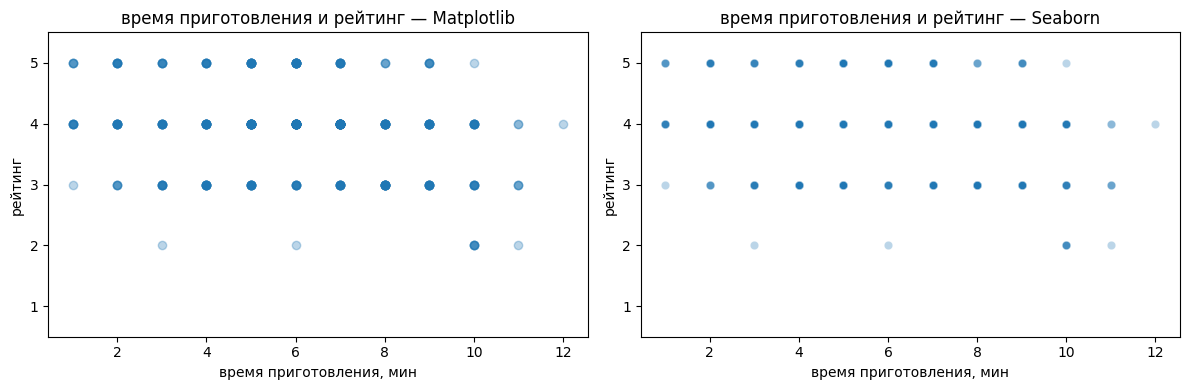

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    df_clean['prep_minutes'],
    df_clean['rating'],
    alpha=0.3
)

sns.scatterplot(
    data=df_clean,
    x='prep_minutes',
    y='rating',
    alpha=0.3,
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'время приготовления и рейтинг — {library}')
    ax.set_xlabel('время приготовления, мин')
    ax.set_ylabel('рейтинг')
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylim(0.5, 5.5)

plt.tight_layout()
plt.show()

6.5

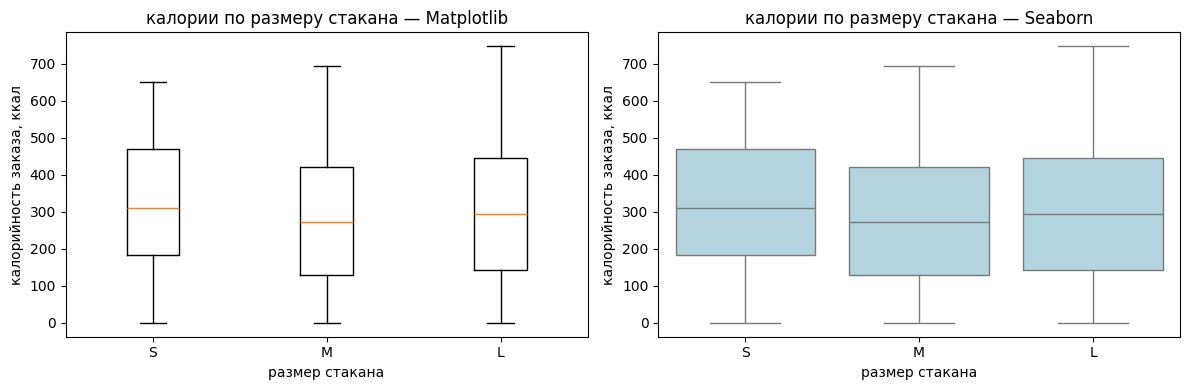

In [13]:
sizes = ['S', 'M', 'L']

calories_by_size = [
    df_clean.loc[df_clean['size'] == size, 'calories']
    for size in sizes
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(calories_by_size)
axes[0].set_xticks([1, 2, 3])
axes[0].set_xticklabels(sizes)

sns.boxplot(
    data=df_clean,
    x='size',
    y='calories',
    order=sizes,
    color='lightblue',
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'калории по размеру стакана — {library}')
    ax.set_xlabel('размер стакана')
    ax.set_ylabel('калорийность заказа, ккал')

plt.tight_layout()
plt.show()

6.6

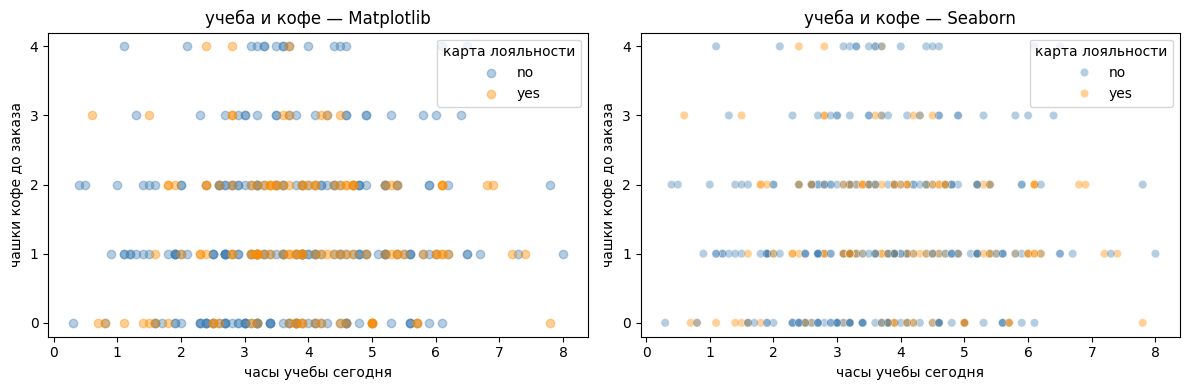

In [14]:
colors = {'no': 'steelblue', 'yes': 'darkorange'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for member, color in colors.items():
    group = df_clean[df_clean['is_member'] == member]

    axes[0].scatter(
        group['study_hours_today'],
        group['prior_coffee_cups'],
        color=color,
        alpha=0.4,
        label=member
    )

axes[0].legend(title='карта лояльности')

sns.scatterplot(
    data=df_clean,
    x='study_hours_today',
    y='prior_coffee_cups',
    hue='is_member',
    hue_order=['no', 'yes'],
    palette=colors,
    alpha=0.4,
    ax=axes[1]
)

axes[1].legend(title='карта лояльности')

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'учеба и кофе — {library}')
    ax.set_xlabel('часы учебы сегодня')
    ax.set_ylabel('чашки кофе до заказа')
    ax.set_yticks(
        sorted(df_clean['prior_coffee_cups'].unique())
    )

plt.tight_layout()
plt.show()

А

payment
card           0.613
campus_card    0.592
cash           0.386
Name: tip, dtype: float64


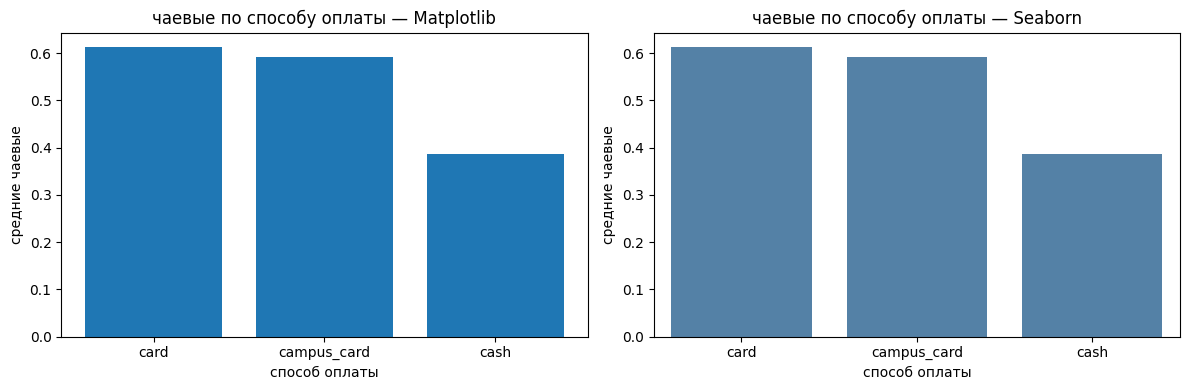

In [15]:
payment_tips = (
    df_clean.groupby('payment')['tip']
    .mean()
    .sort_values(ascending=False)
)

print(payment_tips.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(payment_tips.index, payment_tips.values)

sns.barplot(
    data=payment_tips.rename('mean_tip').reset_index(),
    x='payment',
    y='mean_tip',
    order=payment_tips.index,
    color='steelblue',
    ax=axes[1]
)

for ax, library in zip(axes, ['Matplotlib', 'Seaborn']):
    ax.set_title(f'чаевые по способу оплаты — {library}')
    ax.set_xlabel('способ оплаты')
    ax.set_ylabel('средние чаевые')

plt.tight_layout()
plt.show()

В

In [16]:
morning_food = df_clean[
    (df_clean['food_item'] != 'none') &
    (df_clean['time_slot'] == 'morning')
]

print('количество заказов:', len(morning_food))

drink_counts = morning_food['drink'].value_counts()
print(drink_counts)

if not drink_counts.empty:
    most_popular = drink_counts[
        drink_counts == drink_counts.max()
    ].index.tolist()

    print('самый частый напиток:', ', '.join(most_popular))
else:
    print('заказов по заданным условиям нет.')

количество заказов: 58
drink
cappuccino       13
latte            11
tea               9
smoothie          7
hot_chocolate     7
americano         6
cold_brew         5
Name: count, dtype: int64
самый частый напиток: cappuccino
